# Imports

In [1]:
import polars as pl
import numpy as np
import os
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
import statsmodels.api as sm
from scipy.stats import pearsonr, kendalltau, spearmanr
from scipy import signal
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LogisticRegression

# Load data

In [2]:
def load_data(folder_path):
    print(f"Loading data from {folder_path}")
    return pl.scan_csv(os.path.join(folder_path, "*.csv"))

current_path = os.getcwd()
binance_df = load_data(os.path.join(current_path, 'binance_data/eth-usdt'))
dex_df = load_data(os.path.join(current_path, 'dex_eth_usdt_jan_2025/treated'))

Loading data from /home/puguix/Documents/master-thesis/binance_data/eth-usdt
Loading data from /home/puguix/Documents/master-thesis/dex_eth_usdt_jan_2025/treated


# Convert timestamp to datetime[ms]

In [3]:
binance_df = binance_df.with_columns(pl.from_epoch(pl.col('timestamp'), time_unit='ns').cast(pl.Datetime("ms")).alias('timestamp'))

dex_df = dex_df.with_columns(pl.from_epoch(pl.col('timestamp'), time_unit='s').cast(pl.Datetime("ms")).alias('timestamp'))

# Sort both dataframes by their timestamp index

In [4]:
binance_df = binance_df.set_sorted('timestamp')
dex_df = dex_df.set_sorted('timestamp')

# Trim both dataframes to the common time period

In [5]:
start_time = pl.col('timestamp').min().alias('min_time')
end_time = pl.col('timestamp').max().alias('max_time')

start_time = max(binance_df.select(start_time).collect().item(), dex_df.select(start_time).collect().item())
end_time = min(binance_df.select(end_time).collect().item(), dex_df.select(end_time).collect().item())

binance_df = binance_df.filter(pl.col('timestamp').is_between(start_time, end_time))
dex_df = dex_df.filter(pl.col('timestamp').is_between(start_time, end_time))

print("\n=== Time Range After Alignment ===")
print(f"Start time: {start_time}")
print(f"End time: {end_time}")


=== Time Range After Alignment ===
Start time: 2025-01-01 00:00:05.016000
End time: 2025-01-31 22:58:35


# Compute returns and various order book indicators for binance data

- mid price
- volume imbalance (all 10 levels)
- bid-ask spread
- Bid/Ask pressure near top	(Volume in top 3 levels vs bottom 7)

In [6]:
# Compute mid price, volume imbalance, bid-ask spread, bid/ask pressure
binance_df = binance_df.with_columns(
    ((pl.col('bid_1_price') + pl.col('ask_1_price')) / 2).alias('mid_price')
).with_columns([
    (pl.col('bid_1_size') + pl.col('bid_2_size') + pl.col('bid_3_size') + 
     pl.col('bid_4_size') + pl.col('bid_5_size') + pl.col('bid_6_size') + 
     pl.col('bid_7_size') + pl.col('bid_8_size') + pl.col('bid_9_size') + 
     pl.col('bid_10_size')).alias('total_bid_volume'),
    (pl.col('ask_1_size') + pl.col('ask_2_size') + pl.col('ask_3_size') + 
     pl.col('ask_4_size') + pl.col('ask_5_size') + pl.col('ask_6_size') + 
     pl.col('ask_7_size') + pl.col('ask_8_size') + pl.col('ask_9_size') + 
     pl.col('ask_10_size')).alias('total_ask_volume')
]).with_columns(
    ((pl.col('total_bid_volume') - pl.col('total_ask_volume')) / 
     (pl.col('total_bid_volume') + pl.col('total_ask_volume'))).alias('volume_imbalance')
).with_columns(
    (pl.col('ask_1_price') - pl.col('bid_1_price')).alias('bid_ask_spread')
).with_columns(
    ((pl.col('bid_1_size') + pl.col('bid_2_size') + pl.col('bid_3_size')) /
     (pl.col('bid_4_size') + pl.col('bid_5_size') + pl.col('bid_6_size') + 
      pl.col('bid_7_size') + pl.col('bid_8_size') + pl.col('bid_9_size') + 
      pl.col('bid_10_size'))).alias('bid_pressure')
).with_columns(
    ((pl.col('ask_1_size') + pl.col('ask_2_size') + pl.col('ask_3_size')) /
     (pl.col('ask_4_size') + pl.col('ask_5_size') + pl.col('ask_6_size') + 
      pl.col('ask_7_size') + pl.col('ask_8_size') + pl.col('ask_9_size') + 
      pl.col('ask_10_size'))).alias('ask_pressure')
).with_columns(
    pl.col("mid_price").log().diff().alias("binance_returns")
).filter(pl.col("binance_returns").is_not_null())

print("=== Binance Data Preview ===")
display(binance_df.head().collect(engine='streaming'))
display(binance_df.describe())

=== Binance Data Preview ===


timestamp,exchange,instrument,bid_1_price,bid_1_size,bid_2_price,bid_2_size,bid_3_price,bid_3_size,bid_4_price,bid_4_size,bid_5_price,bid_5_size,bid_6_price,bid_6_size,bid_7_price,bid_7_size,bid_8_price,bid_8_size,bid_9_price,bid_9_size,bid_10_price,bid_10_size,ask_1_price,ask_1_size,ask_2_price,ask_2_size,ask_3_price,ask_3_size,ask_4_price,ask_4_size,ask_5_price,ask_5_size,ask_6_price,ask_6_size,ask_7_price,ask_7_size,ask_8_price,ask_8_size,ask_9_price,ask_9_size,ask_10_price,ask_10_size,mid_price,total_bid_volume,total_ask_volume,volume_imbalance,bid_ask_spread,bid_pressure,ask_pressure,binance_returns
datetime[ms],str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,i64,i64,f64,i64,f64,f64,f64
2025-01-01 00:00:05.115,"""binance""","""ethusdt""",3337410000000,5113100000,3337400000000,2000000,3337380000000,4700000,3337330000000,1935800000,3337300000000,11500000,3337290000000,1572800000,3337280000000,791500000,3337230000000,1600000,3337220000000,100500000,3337210000000,2012000000,3337420000000,50899100000,3337430000000,5838600000,3337440000000,10808000000,3337450000000,3500000,3337470000000,2000000,3337480000000,4305000000,3337490000000,1500000,3337560000000,2000000,3337570000000,2000000,3337580000000,2000000,3.3374e12,11545500000,71863700000,-0.72316,10000000,0.796769,15.642821,0.0
2025-01-01 00:00:05.215,"""binance""","""ethusdt""",3337290000000,10400000,3337280000000,793500000,3337230000000,3600000,3337220000000,3600000,3337210000000,2000000,3337180000000,2000000,3337140000000,3100000,3337120000000,9000000,3337090000000,1068900000,3337050000000,7400000,3337300000000,41848700000,3337320000000,3960400000,3337340000000,4952000000,3337350000000,1500000,3337390000000,181400000,3337400000000,2633000000,3337410000000,21506200000,3337420000000,10728100000,3337430000000,510200000,3337440000000,10809100000,3.3373e12,1903500000,97130600000,-0.961559,10000000,0.73677,1.094709,-0.000036
2025-01-01 00:00:05.315,"""binance""","""ethusdt""",3337230000000,1559400000,3337220000000,8400000,3337180000000,2000000,3337140000000,4700000,3337120000000,10600000,3337050000000,7400000,3337020000000,3100000,3337000000000,299600000,3336990000000,50000000,3336940000000,3100000,3337240000000,39500900000,3337280000000,3958400000,3337290000000,27545900000,3337300000000,1022000000,3337320000000,2000000,3337340000000,4952000000,3337350000000,3500000,3337390000000,181900000,3337400000000,2633000000,3337410000000,599000000,3.3372e12,1948300000,80398600000,-0.952681,10000000,4.147424,7.559052,-0.000018
2025-01-01 00:00:05.415,"""binance""","""ethusdt""",3337230000000,6963000000,3337180000000,2000000,3337140000000,4700000,3337120000000,9000000,3337050000000,7400000,3337020000000,4700000,3337000000000,1497600000,3336990000000,50000000,3336940000000,3100000,3336930000000,603700000,3337240000000,35063400000,3337280000000,16645800000,3337290000000,2000000,3337300000000,22000000,3337320000000,3500000,3337340000000,2000000,3337350000000,3500000,3337390000000,181900000,3337400000000,2635000000,3337410000000,599000000,3.3372e12,9145200000,55158100000,-0.71556,10000000,3.203723,15.002234,0.0
2025-01-01 00:00:05.515,"""binance""","""ethusdt""",3337230000000,76600000,3337200000000,1198800000,3337180000000,2000000,3337140000000,4700000,3337120000000,9000000,3337050000000,7400000,3337020000000,4700000,3337000000000,898600000,3336990000000,50000000,3336940000000,1040500000,3337240000000,49870300000,3337270000000,9419000000,3337280000000,3960400000,3337290000000,3500000,3337300000000,2000000,3337320000000,3500000,3337340000000,2000000,3337350000000,2000000,3337390000000,183400000,3337400000000,2635000000,3.3372e12,3292300000,66081100000,-0.905085,10000000,0.633977,22.338666,0.0


statistic,timestamp,exchange,instrument,bid_1_price,bid_1_size,bid_2_price,bid_2_size,bid_3_price,bid_3_size,bid_4_price,bid_4_size,bid_5_price,bid_5_size,bid_6_price,bid_6_size,bid_7_price,bid_7_size,bid_8_price,bid_8_size,bid_9_price,bid_9_size,bid_10_price,bid_10_size,ask_1_price,ask_1_size,ask_2_price,ask_2_size,ask_3_price,ask_3_size,ask_4_price,ask_4_size,ask_5_price,ask_5_size,ask_6_price,ask_6_size,ask_7_price,ask_7_size,ask_8_price,ask_8_size,ask_9_price,ask_9_size,ask_10_price,ask_10_size,mid_price,total_bid_volume,total_ask_volume,volume_imbalance,bid_ask_spread,bid_pressure,ask_pressure,binance_returns
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""25525872""","""25525872""","""25525872""",2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7,2.5525872e7
"""null_count""","""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2025-01-16 09:21:03.710000""",null,null,3.3318e12,3.2596e10,3.3318e12,2.0296e9,3.3318e12,1.4524e9,3.3318e12,1.2482e9,3.3317e12,1.1458e9,3.3317e12,1.3274e9,3.3317e12,1.4631e9,3.3317e12,1.6036e9,3.3317e12,1.7243e9,3.3316e12,1.8369e9,3.3318e12,3.3914e10,3.3318e12,2.0805e9,3.3318e12,1.3943e9,3.3319e12,1.2016e9,3.3319e12,1.0486e9,3.3319e12,1.1194e9,3.3319e12,1.1779e9,3.3319e12,1.2236e9,3.3319e12,1.3312e9,3.3320e12,1.4400e9,3.3318e12,4.6428e10,4.5931e10,0.015181,1.0576e7,17.986779,57.795475,-5.0851e-10
"""std""",null,null,null,1.4925e11,3.3076e10,1.4925e11,9.4443e9,1.4925e11,7.3550e9,1.4925e11,5.3582e9,1.4925e11,5.7333e9,1.4925e11,5.5680e9,1.4924e11,5.8696e9,1.4924e11,7.9398e9,1.4924e11,7.5247e9,1.4924e11,7.6816e9,1.4925e11,3.7200e10,1.4925e11,1.0782e10,1.4925e11,7.3421e9,1.4925e11,5.7545e9,1.4925e11,5.7893e9,1.4925e11,6.7918e9,1.4925e11,7.9727e9,1.4925e11,6.6664e9,1.4925e11,7.0594e9,1.4925e11,7.3460e9,1.4925e11,4.6497e10,5.2026e10,0.66028,2.9031e7,203.402452,423.402536,0.000028
"""min""","""2025-01-01 00:00:05.115000""","""binance""","""ethusdt""",2.9200e12,100000.0,2.9200e12,100000.0,2.9200e12,100000.0,2.9200e12,100000.0,2.9199e12,100000.0,2.9199e12,100000.0,2.9199e12,100000.0,2.9199e12,100000.0,2.9198e12,100000.0,2.9198e12,100000.0,2.9202e12,100000.0,2.9237e12,100000.0,2.9256e12,100000.0,2.9256e12,100000.0,2.9258e12,100000.0,2.9258e12,100000.0,2.9258e12,100000.0,2.9259e12,100000.0,2.9259e12,100000.0,2.9261e12,100000.0,2.9201e12,1.45e7,1.45e7,-0.999919,1e7,0.000003,0.000005,-0.009986
"""25%""","""2025-01-08 16:43:03.115000""",null,null,3.2395e12,9.2318e9,3.2394e12,3.6e6,3.2394e12,3e6,3.2394e12,3.2e6,3.2394e12,3.1e6,3.2394e12,1.8e6,3.2394e12,2.9e6,3.2393e12,3.1e6,3.2393e12,3.2e6,3.2393e12,3.3e6,3.2395e12,9.3147e9,3.2395e12,4.7e6,3.2395e12,4.7e6,3.2395e12,4.7e6,3.2395e12,4.6e6,3.2396e12,2e6,3.2396e12,2e6,3.2396e12,2e6,3.2396e12,2e6,3.2396e12,2e6,3.2395e12,1.5361e10,1.3678e10,-0.611641,1e7,1.76707,2.505278,0.0
"""50%""","""2025-01-16 05:31:58.515000""",null,null,3.3071e12,2.5030e10,3.3071e12,3.05e7,3.3071e12,6.6e6,3.3071e12,6.4e6,3.3071e12,6.4e6,3.3070e12,2.95e7,3.3070e12,1.012e8,3.3070e12,2.5e8,3.3070e12,3.752e8,3.3070e12,5.14e8,3.3071e12,2.6014e10,3.3072e12,1.06e7,3.3072e12,6.6e6,3.3072e12,6.6e6,3.3072e12,6.4e6,3.3072e12,4.7e6,3.3072e12,4.9e6,3.3072e12,5.

# Compute returns for Uniswap

In [7]:
dex_df = dex_df.with_columns(
    pl.col("eth_usdt").log().diff().alias("dex_returns")
).filter(pl.col("dex_returns").is_not_null())

print("\n=== DEX Data Preview ===")
display(dex_df.head().collect())
display(dex_df.describe())


=== DEX Data Preview ===


eth_reserves,usdt_reserves,timestamp,eth_usdt,dex_returns
f64,f64,datetime[ms],f64,f64
1.0390e22,3.4704e13,2025-01-01 00:01:59,3.3402e12,0.00001
1.0390e22,3.4704e13,2025-01-01 00:04:47,3.3402e12,-7.9440e-7
1.0390e22,3.4704e13,2025-01-01 00:06:23,3.3402e12,7.2474e-7
1.0390e22,3.4704e13,2025-01-01 00:06:35,3.3403e12,0.000024
1.0389e22,3.4705e13,2025-01-01 00:06:47,3.3405e12,0.00006


statistic,eth_reserves,usdt_reserves,timestamp,eth_usdt,dex_returns
str,f64,f64,str,f64,f64
"""count""",59771.0,59771.0,"""59771""",59771.0,59771.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0
"""mean""",1.0909e22,3.6353e13,"""2025-01-16 00:52:33.614000""",3.3367e12,-2.4619e-7
"""std""",1.5220e21,4.9295e12,null,1.5322e11,0.000494
"""min""",8.3814e21,2.7099e13,"""2025-01-01 00:01:59""",2.9341e12,-0.01318
"""25%""",1.0210e22,3.3824e13,"""2025-01-08 11:01:47""",3.2424e12,-0.000022
"""50%""",1.0399e22,3.4723e13,"""2025-01-16 04:13:47""",3.3095e12,0.000004
"""75%""",1.0704e22,3.6477e13,"""2025-01-23 02:25:35""",3.3995e12,0.000047
"""max""",1.5060e22,4.8385e13,"""2025-01-31 22:58:35""",3.7359e12,0.009474


# Plot the prices on both exchange

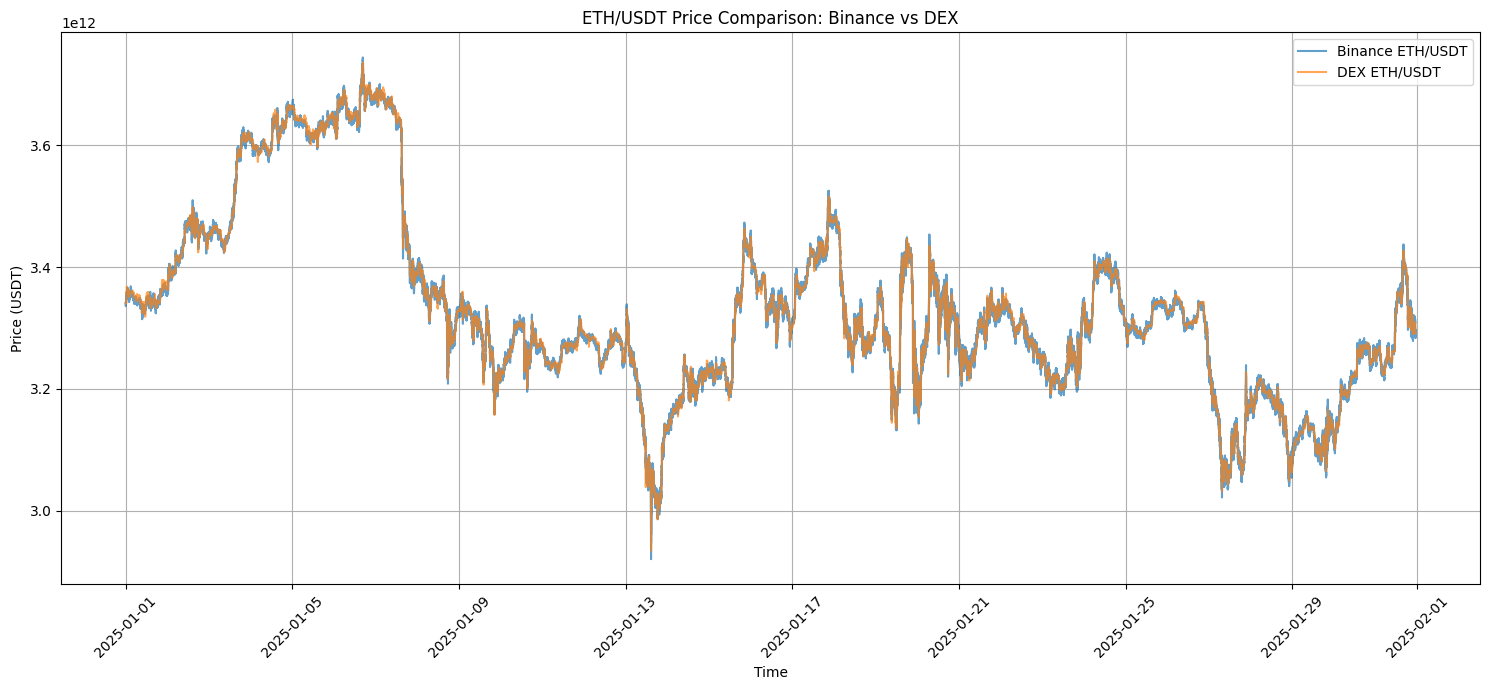

In [8]:
plt.figure(figsize=(15, 7))

# Plot Binance data
plt.plot(binance_df.select('timestamp').collect(), binance_df.select('mid_price').collect(), label='Binance ETH/USDT', alpha=0.7)

# Plot DEX data 
plt.plot(dex_df.select('timestamp').collect(), dex_df.select('eth_usdt').collect(), label='DEX ETH/USDT', alpha=0.7)

plt.title('ETH/USDT Price Comparison: Binance vs DEX')
plt.xlabel('Time')
plt.ylabel('Price (USDT)')
plt.legend()
plt.grid(True)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Downsample the Binance data to match the Uniswap data for some of the following tests

In [9]:
downsampled_df = dex_df.join_asof(
    binance_df, 
    on="timestamp", 
    strategy="nearest"
).filter(pl.col("binance_returns").is_not_null())

# Join DEX data with the Binance data
downsampled_backward = dex_df.join_asof(
    binance_df,
    on="timestamp",
    strategy="backward"  # get last Binance row before each DEX ts
).filter(pl.col("binance_returns").is_not_null())

downsampled_forward = dex_df.join_asof(
    binance_df,
    on="timestamp",
    strategy="forward"  # get first Binance row after each DEX ts
).filter(pl.col("binance_returns").is_not_null())

# Perform Augmented Dickey-Fuller test on both return series

Can't perform the ADF test on the all binance returns, because the data is too large. So we split the data in multiple chunks

In [10]:
# ADF test for DEX returns
dex_returns_adf = adfuller(dex_df.select('dex_returns').collect(engine='streaming'))
print("ADF Test for DEX Returns:")
print(f"ADF Statistic: {dex_returns_adf[0]}")
print(f"p-value: {dex_returns_adf[1]}")
print(f"Critical Values:")
for key, value in dex_returns_adf[4].items():
    print(f"\t{key}: {value}")
print(f"{'Stationary' if dex_returns_adf[1] < 0.05 else 'Non-stationary'} (at 5% significance level)")

ADF Test for DEX Returns:
ADF Statistic: -31.522008737362363
p-value: 0.0
Critical Values:
	1%: -3.4304595168746097
	5%: -2.8615884043829163
	10%: -2.5667957640219328
Stationary (at 5% significance level)


In [11]:
# ADF test for Binance returns
downsampled_adf = adfuller(downsampled_df.select('binance_returns').collect(engine='streaming'))
print("ADF Test for DEX Returns:")
print(f"ADF Statistic: {downsampled_adf[0]}")
print(f"p-value: {downsampled_adf[1]}")
print(f"Critical Values:")
for key, value in downsampled_adf[4].items():
    print(f"\t{key}: {value}")
print(f"{'Stationary' if dex_returns_adf[1] < 0.05 else 'Non-stationary'} (at 5% significance level)")

ADF Test for DEX Returns:
ADF Statistic: -30.064576070012357
p-value: 0.0
Critical Values:
	1%: -3.4304595223772854
	5%: -2.8615884068149495
	10%: -2.56679576531643
Stationary (at 5% significance level)


# Calculate Spearman rank correlation for DEX vs Binance returns

In [10]:
spearman, p_value_spearman = spearmanr(
    downsampled_df.select('dex_returns').collect(engine='streaming'),
    downsampled_df.select('binance_returns').collect(engine='streaming')
)

print("\nSpearman Rank Correlation Test Results:")
print(f"DEX vs Binance Returns:")
print(f"  Correlation coefficient: {spearman:.6f}")
print(f"  p-value: {p_value_spearman:.6f}")
print(f"  {'Significant' if p_value_spearman < 0.05 else 'Not significant'} correlation at 5% level")



Spearman Rank Correlation Test Results:
DEX vs Binance Returns:
  Correlation coefficient: 0.033113
  p-value: 0.000000
  Significant correlation at 5% level


# Perform Pearson correlation test between DEX and Binance returns

In [11]:
pearson, p_value_pearson = pearsonr(downsampled_df.select('dex_returns').collect(engine='streaming'), downsampled_df.select('binance_returns').collect(engine='streaming'))

# Print results
print("\nPearson Correlation Test Results:")
print(f"DEX vs Binance Returns:")
print(f"  Correlation coefficient: {float(pearson[0]):.6f}")
print(f"  p-value: {float(p_value_pearson[0]):.6f}")
print(f"  {'Significant' if float(p_value_pearson[0]) < 0.05 else 'Not significant'} correlation at 5% level")



Pearson Correlation Test Results:
DEX vs Binance Returns:
  Correlation coefficient: 0.148889
  p-value: 0.000000
  Significant correlation at 5% level


# Perform Kendall rank correlation test between DEX and Binance returns

In [12]:
kendall, p_value_kendall = kendalltau(
    downsampled_df.select('dex_returns').collect(engine='streaming'), 
    downsampled_df.select('binance_returns').collect(engine='streaming')
)

print("\nKendall Rank Correlation Test Results:")
print(f"DEX vs Binance Returns:")
print(f"  Correlation coefficient: {kendall:.6f}")
print(f"  p-value: {p_value_kendall:.6f}")
print(f"  {'Significant' if p_value_kendall < 0.05 else 'Not significant'} correlation at 5% level")


Kendall Rank Correlation Test Results:
DEX vs Binance Returns:
  Correlation coefficient: 0.026295
  p-value: 0.000000
  Significant correlation at 5% level


# Calculate cross-correlation between Binance mid returns and DEX returns using the Hayashi-Yoshida estimator
Ticks are not the same, so we need to use the Hayashi-Yoshida estimator to calculate the cross-correlation.

To estimate the cross-correlation function with a lag ($\ell$), a lagged version of the estimator is used:

$\hat{\rho}(\ell) = \frac{\sum_{i,j} r^X_i r^Y_j 1_{{O^\ell_{ij} \neq \emptyset}}}{\sqrt{\sum_i (r^X_i)^2 \sum_j (r^Y_j)^2}}$

where $O^\ell_{ij} = ]t_{i-1}, t_i] \cap ]s_{j-1} - \ell, s_j - \ell]$ represents the time interval between the $i$-th transaction of asset X and the lagged time interval of the $j$-th transaction of asset Y.

In [ ]:
lags = np.arange(-20, 21)
lag_ms_list = lags * 1_000

# Build correlation computations for each lag
corr_exprs = []

for lag, lag_ms in zip(lags, lag_ms_list):
    # Shift DEX timestamps by lag
    shifted_dex = dex_df.select([
        (pl.col("timestamp").cast(pl.Int64) + lag_ms).cast(pl.Datetime("ms")).alias("timestamp"),
        pl.col("dex_returns")
    ])
    
    # Join on nearest timestamp (asynchronous-safe)
    joined = binance_df.join_asof(
        shifted_dex,
        on="timestamp",
        strategy="nearest"
    ).select(
        pl.corr("binance_returns", "dex_returns").alias(f"lag_{lag}")
    )

    corr_exprs.append(joined)

# Combine all correlation results
lazy_corrs = pl.concat(corr_exprs, how="horizontal")

# Collect the result
result_row = lazy_corrs.collect(engine='streaming').row(0)

# Turn into a tidy DataFrame with lag/correlation
lag_corrs = pl.DataFrame({
    "lag": lags,
    "correlation": result_row
})

lag_corrs.transpose()

# Calculate lead/lag ratio

In [11]:
lead_lag_ratio = (
    lag_corrs.lazy()
    .with_columns([
        pl.when(pl.col("lag") > 0).then(pl.col("correlation") ** 2).otherwise(0.0).alias("lead_power_term"),
        pl.when(pl.col("lag") < 0).then(pl.col("correlation") ** 2).otherwise(0.0).alias("lag_power_term"),
    ])
    .select([
        pl.sum("lead_power_term").alias("lead_power"),
        pl.sum("lag_power_term").alias("lag_power"),
    ])
    .with_columns([
        (pl.col("lead_power") / pl.col("lag_power")).alias("lead_lag_ratio")
    ])
    .collect()
)

lead_lag_ratio


lead_power,lag_power,lead_lag_ratio
f64,f64,f64
0.003508,0.012679,0.276695


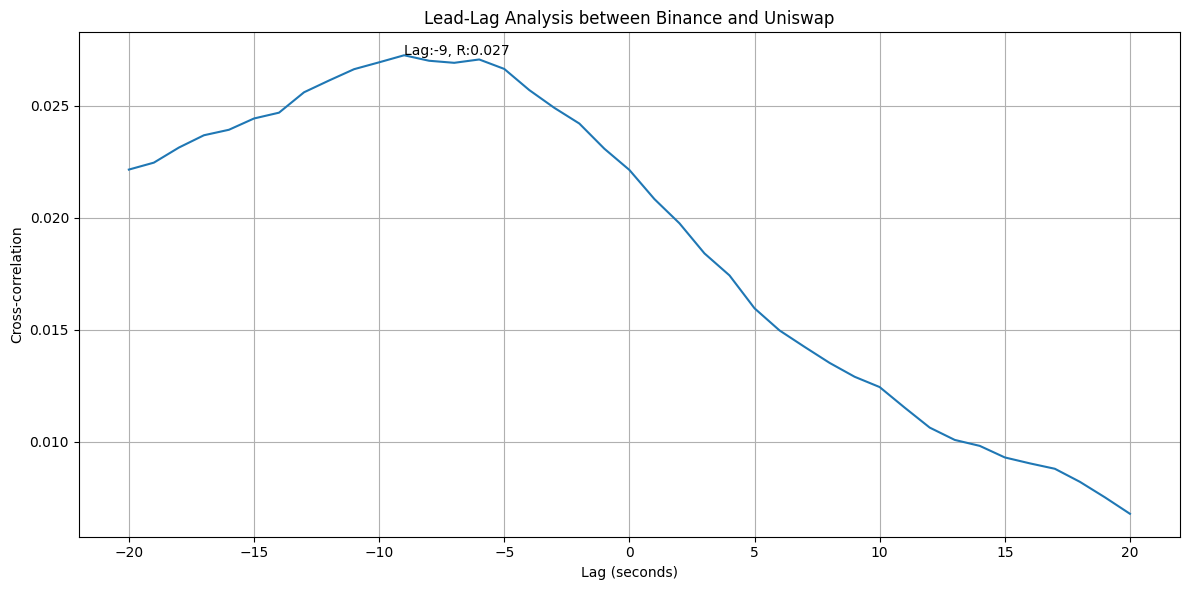

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(lag_corrs['lag'], lag_corrs['correlation'])

# Add annotation for maximum correlation
max_corr = lag_corrs['correlation'].max()
max_lag = lag_corrs.filter(pl.col('correlation') == max_corr)['lag'][0]
plt.annotate(f'Lag:{max_lag}, R:{max_corr:.3f}', xy=(max_lag, max_corr))

plt.xlabel('Lag (seconds)')
plt.ylabel('Cross-correlation')
plt.title('Lead-Lag Analysis between Binance and Uniswap')
plt.grid(True)

plt.tight_layout()
plt.show()


# Epps-Poulsen Covariance Estimator

In [ ]:
bandwidth_ns = 10_000  # 10 seconds in milliseconds

# Step 1: Join
joined = binance_df.join_asof(
    dex_df,
    on="timestamp",
    strategy="nearest",
    coalesce=False,
    suffix="_dex"
).with_columns([
    (pl.col("timestamp") - pl.col("timestamp_dex")).alias("time_diff"),
])

filtered = joined.filter(
    (pl.col("time_diff").abs() <= bandwidth_ns)
)

def gaussian_kernel(expr):
    return (-(expr.cast(pl.Float64) / bandwidth_ns) ** 2 / 2).exp()

# Step 2: Compute kernel weights
weighted = filtered.with_columns([
    gaussian_kernel(pl.col("time_diff")).alias("kernel_weight"),
]).with_columns([
    (pl.col("binance_returns") * pl.col("dex_returns") * pl.col("kernel_weight")).alias("weighted_product")
])

# Step 3: Aggregate
covariance = weighted.select(
    (pl.col("weighted_product").sum() / pl.col("kernel_weight").sum()).alias("epps_poulsen_covariance")
)

covariance.collect(engine='streaming')
# joined.head().collect(engine='streaming')

epps_poulsen_covariance
f64
5.2012e-10


# Perform Granger causality tests in both directions  

In [17]:
# window_size = 30

# Create a weighted moving average on binance_returns
# binance_weighted_avg = (
#     binance_returns_df
#     .sort("timestamp")
#     .with_columns([
#         pl.col("binance_returns").rolling_mean(
#             window_size=window_size,
#             weights=list(range(1, window_size+1)),  # Increasing weights for more recent values
#             min_samples=1
#         ).alias("binance_returns_weighted"),
#         pl.col("binance_returns").rolling_mean(
#             window_size=window_size,
#             min_samples=1
#         ).alias("binance_returns_mean")
#     ])
# )

maxlag = 20  # Testing up to 20 lags

# Test if Binance Granger-causes DEX
print("Testing if Binance Granger-causes DEX:")
gc_binance_dex = grangercausalitytests(downsampled_backward.select(['dex_returns', 'binance_returns']).collect(engine='streaming'), maxlag=maxlag)

# Test if DEX Granger-causes Binance
print("\nTesting if DEX Granger-causes Binance:")
gc_dex_binance = grangercausalitytests(downsampled_forward.select(['binance_returns', 'dex_returns']).collect(engine='streaming'), maxlag=maxlag)

# Find the minimum p-value for each test across all lags (lower p-value = stronger evidence of causality)
min_binance_dex_pval = min((gc_binance_dex[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))
min_dex_binance_pval = min((gc_dex_binance[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))

# # Store the results with both p-value and corresponding lag
# all_pvals = {
#     "Binance -> DEX": min_binance_dex_pval,
#     "DEX -> Binance": min_dex_binance_pval,
# }

# strongest_link = min(all_pvals.items(), key=lambda x: x[1][0])

# # Print the strongest causal relationship with lag
# print("\nStrongest Granger causal relationship:")
# print(f"{strongest_link[0]} with p-value: {strongest_link[1][0]} at lag {strongest_link[1][1]}")

# # Print all p-values for comparison with their corresponding lags
# print("\nAll minimum p-values across lags (lower = stronger evidence):")
# for relationship, (p_value, lag) in sorted(all_pvals.items(), key=lambda x: x[1][0]):
#     print(f"{relationship}: p-value = {p_value} at lag {lag}")

Testing if Binance Granger-causes DEX:

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=12.6410 , p=0.0004  , df_denom=59767, df_num=1
ssr based chi2 test:   chi2=12.6417 , p=0.0004  , df=1
likelihood ratio test: chi2=12.6403 , p=0.0004  , df=1
parameter F test:         F=12.6410 , p=0.0004  , df_denom=59767, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=31.3489 , p=0.0000  , df_denom=59764, df_num=2
ssr based chi2 test:   chi2=62.7031 , p=0.0000  , df=2
likelihood ratio test: chi2=62.6702 , p=0.0000  , df=2
parameter F test:         F=31.3489 , p=0.0000  , df_denom=59764, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=20.1198 , p=0.0000  , df_denom=59761, df_num=3
ssr based chi2 test:   chi2=60.3665 , p=0.0000  , df=3
likelihood ratio test: chi2=60.3360 , p=0.0000  , df=3
parameter F test:         F=20.1198 , p=0.0000  , df_denom=59761, df_num=3

Granger Causality
number of lags (no zero)

# Perform spectral analysis and coherence calculation

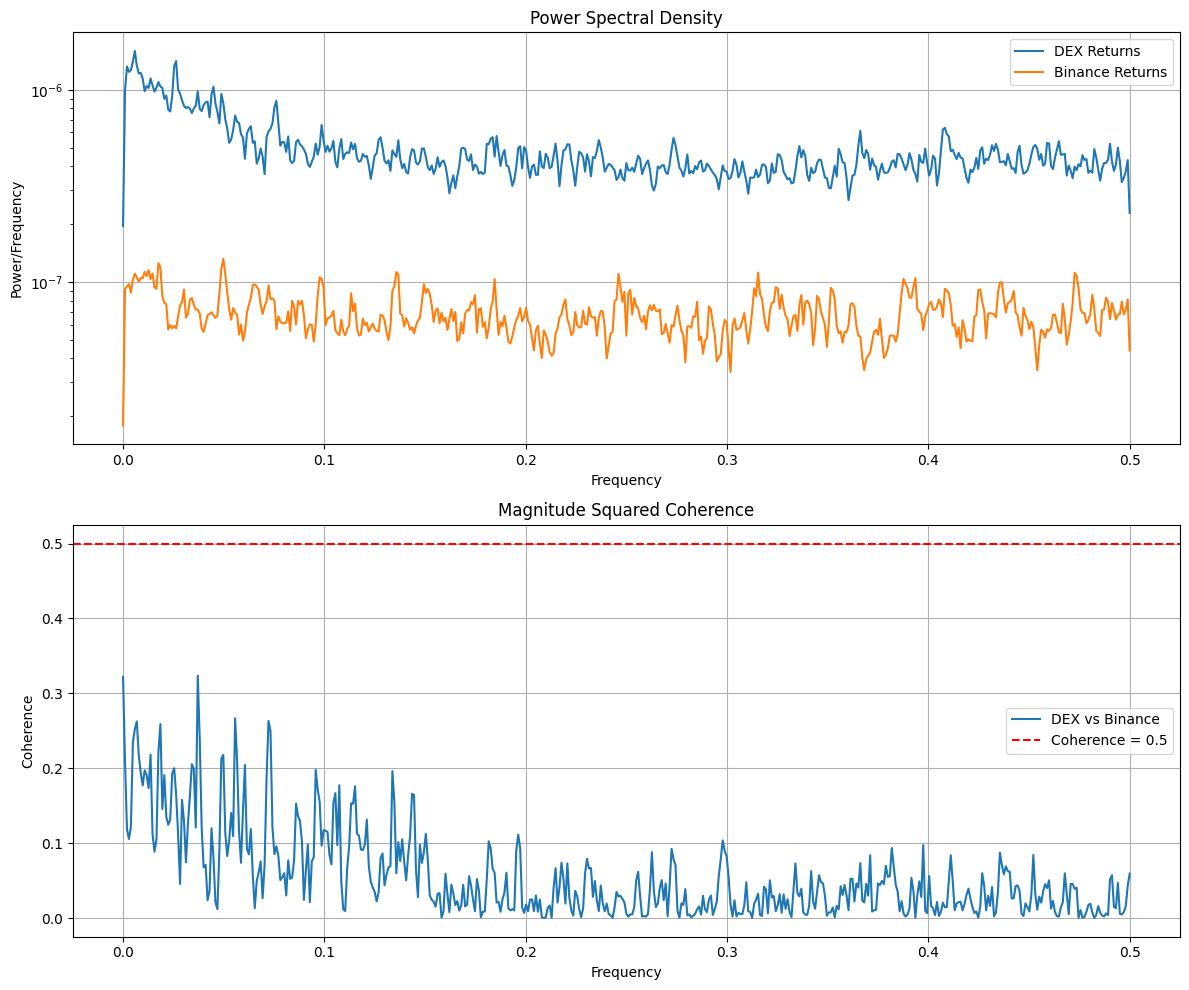


Average Coherence in Different Frequency Bands:
DEX vs Binance:
  Low frequency (0-0.1): 0.1284
  Mid frequency (0.1-0.3): 0.0457
  High frequency (0.3+): 0.0270

Frequency with Maximum Coherence:
DEX vs Binance: 0.037109 (Coherence: 0.3235)


In [18]:
# Extract the return series
dex_returns = np.array(downsampled_df.select('dex_returns').collect(engine='streaming')).flatten()
binance_returns = np.array(downsampled_df.select('binance_returns').collect(engine='streaming')).flatten()

# Calculate power spectral density for each series
f_dex, psd_dex = signal.welch(dex_returns, nperseg=1024)
f_binance, psd_binance = signal.welch(binance_returns, nperseg=1024)

# Calculate coherence between DEX and Binance returns
f_coh, coherence = signal.coherence(dex_returns, binance_returns, nperseg=1024)

# Plot the power spectral densities
plt.figure(figsize=(12, 10))

# PSD plots
plt.subplot(2, 1, 1)
plt.semilogy(f_dex, psd_dex, label='DEX Returns')
plt.semilogy(f_binance, psd_binance, label='Binance Returns')
plt.title('Power Spectral Density')
plt.xlabel('Frequency')
plt.ylabel('Power/Frequency')
plt.legend()
plt.grid(True)

# Coherence plot
plt.subplot(2, 1, 2)
plt.plot(f_coh, coherence, label='DEX vs Binance')
plt.title('Magnitude Squared Coherence')
plt.xlabel('Frequency')
plt.ylabel('Coherence')
plt.axhline(y=0.5, color='r', linestyle='--', label='Coherence = 0.5')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Calculate and print the average coherence in different frequency bands
low_freq_idx = (f_coh > 0) & (f_coh < 0.1)
mid_freq_idx = (f_coh >= 0.1) & (f_coh < 0.3)
high_freq_idx = f_coh >= 0.3

print("\nAverage Coherence in Different Frequency Bands:")
print("DEX vs Binance:")
print(f"  Low frequency (0-0.1): {np.mean(coherence[low_freq_idx]):.4f}")
print(f"  Mid frequency (0.1-0.3): {np.mean(coherence[mid_freq_idx]):.4f}")
print(f"  High frequency (0.3+): {np.mean(coherence[high_freq_idx]):.4f}")

# Find the frequency with maximum coherence
max_coh_idx = np.argmax(coherence)
print("\nFrequency with Maximum Coherence:")
print(f"DEX vs Binance: {f_coh[max_coh_idx]:.6f} (Coherence: {coherence[max_coh_idx]:.4f})")

# Perform classification on returns (positiv vs negativ)

In [12]:
# Define features and target
features = ['price_diff', 'volume_imbalance', 'bid_ask_spread', 'bid_pressure', 'ask_pressure']
target = 'dex_returns_positiv'

downsampled_backward = downsampled_backward.with_columns([
    (pl.col("dex_returns") > 0).alias("dex_returns_positiv"),
    (pl.col("mid_price") - pl.col("eth_usdt").shift(1)).alias("price_diff")
])

# Train/test split as before
collected_df = downsampled_backward.select(features + [target]).collect()
train_size = int(len(collected_df) * 0.75)

train_df = downsampled_backward.slice(0, train_size)
test_df = downsampled_backward.slice(train_size, len(collected_df))

# Prepare X and y
X_train = train_df.select(features).fill_null(0).collect()
y_train = train_df.select(target).fill_null(0).collect()
X_test = test_df.select(features).fill_null(0).collect()
y_test = test_df.select(target).fill_null(0).collect()

X_train_np = X_train.to_numpy()
y_train_np = y_train.to_numpy().flatten()
X_test_np = X_test.to_numpy()
y_test_np = y_test.to_numpy().flatten()

# Logistic Regression
clf = LogisticRegression()
clf.fit(X_train_np, y_train_np)

# Predict
y_pred = clf.predict(X_test_np)

# Evaluate
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test_np, y_pred))
print(classification_report(y_test_np, y_pred))


Accuracy: 0.6250418256039617
              precision    recall  f1-score   support

       False       0.58      0.64      0.61      6828
        True       0.67      0.61      0.64      8115

    accuracy                           0.63     14943
   macro avg       0.63      0.63      0.62     14943
weighted avg       0.63      0.63      0.63     14943



# Perform linear regression on the DEX data

In [13]:
# Define features and target
features = ['mid_price', 'volume_imbalance', 'bid_ask_spread', 'bid_pressure', 'ask_pressure']
target = 'eth_usdt'

# Collect to compute training/testing split
collected_df = downsampled_backward.collect()
train_size = int(len(collected_df) * 0.75)

# Re-split as LazyFrames
train_df = downsampled_backward.slice(0, train_size)
test_df = downsampled_backward.slice(train_size, len(collected_df))

# Fill nulls and collect
X_train = train_df.select(features).fill_null(0).collect().to_numpy()
y_train = train_df.select([target]).fill_null(0).collect().to_numpy().flatten()

X_test = test_df.select(features).fill_null(0).collect().to_numpy()
y_test = test_df.select([target]).fill_null(0).collect().to_numpy().flatten()

# Add constant (intercept) to features
X_train_with_const = sm.add_constant(X_train)
X_test_with_const = sm.add_constant(X_test)

# Fit the model
model = sm.OLS(y_train, X_train_with_const).fit()

# Predict
y_pred = model.predict(X_test_with_const)

# Results
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
normalized_rmse = rmse / np.mean(y_test) 
r2 = model.rsquared

print(f"Normalized Root Mean Squared Error: {normalized_rmse * 100:.3f}%")
print(f"R² Score: {r2:.6f}")

summary_df = pl.DataFrame({
    "Feature": ["Intercept"] + features,
    "Coefficient": model.params.round(6),
    "P-Value": model.pvalues.round(6),
    "T-Stat": model.tvalues.round(6)
})

print(summary_df)

Normalized Root Mean Squared Error: 0.188%
R² Score: 0.998221
shape: (6, 4)
┌──────────────────┬────────────────┬─────────┬─────────────┐
│ Feature          ┆ Coefficient    ┆ P-Value ┆ T-Stat      │
│ ---              ┆ ---            ┆ ---     ┆ ---         │
│ str              ┆ f64            ┆ f64     ┆ f64         │
╞══════════════════╪════════════════╪═════════╪═════════════╡
│ Intercept        ┆ -7.8879e9      ┆ 0.0     ┆ -11.697399  │
│ mid_price        ┆ 1.002508       ┆ 0.0     ┆ 5014.306437 │
│ volume_imbalance ┆ -5.6426e8      ┆ 0.0     ┆ -12.113108  │
│ bid_ask_spread   ┆ 2.619188       ┆ 0.0     ┆ 5.222555    │
│ bid_pressure     ┆ 1.4244e6       ┆ 0.0     ┆ 6.695196    │
│ ask_pressure     ┆ -147672.302132 ┆ 0.05947 ┆ -1.884747   │
└──────────────────┴────────────────┴─────────┴─────────────┘


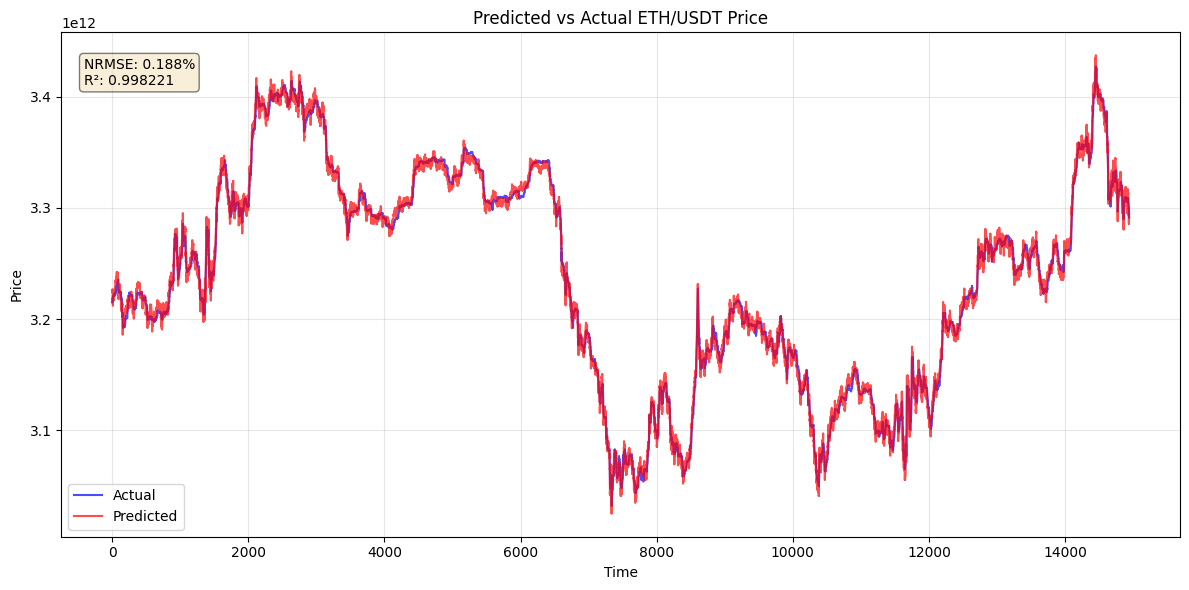

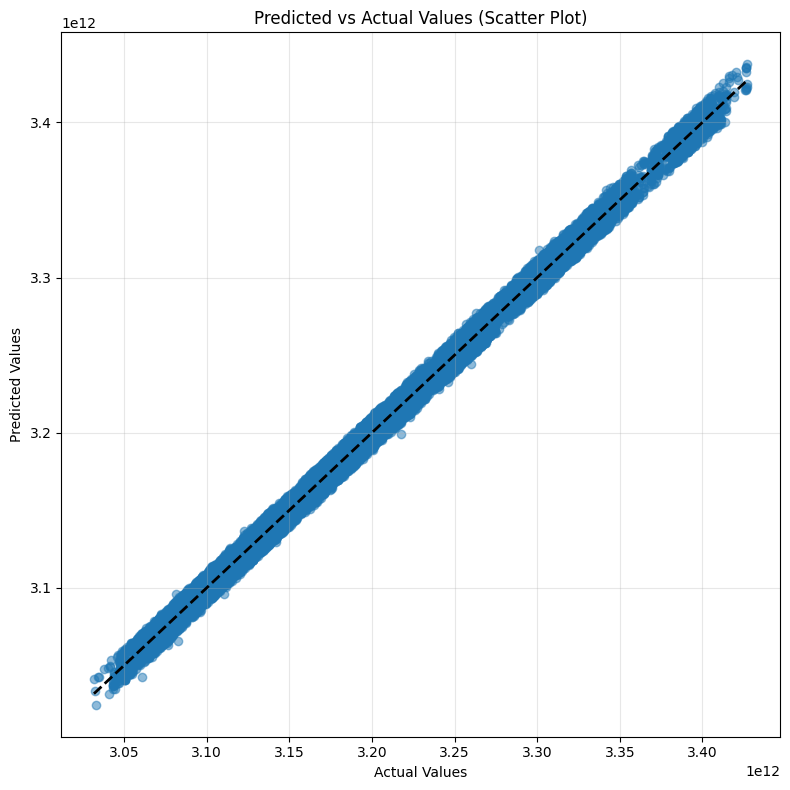

In [14]:
# Create a plot to compare predictions vs actual values
plt.figure(figsize=(12, 6))

# Create a time index for the x-axis
time_index = np.arange(len(y_test))

# Plot actual values
plt.plot(time_index, y_test, label='Actual', color='blue', alpha=0.7)

# Plot predicted values
plt.plot(time_index, y_pred, label='Predicted', color='red', alpha=0.7)

# Add a title and labels
plt.title('Predicted vs Actual ETH/USDT Price')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.grid(True, alpha=0.3)

# Add a text box with model performance metrics
textstr = f'NRMSE: {normalized_rmse * 100:.3f}%\nR²: {r2:.6f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
plt.text(0.02, 0.95, textstr, transform=plt.gca().transAxes, fontsize=10,
         verticalalignment='top', bbox=props)

# Show the plot
plt.tight_layout()
plt.show()

# Also create a scatter plot to visualize correlation
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.title('Predicted vs Actual Values (Scatter Plot)')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
